# Prediction du changement d'insuline — Arbre de decision & methodes ensemblistes

**Dataset** : UCI Diabetes 130-US Hospitals (version nettoyee `cleaned_common.parquet` de la branche `preparation`).

**Cible** : `insulin_change` = 1 si la dose d'insuline a ete modifiee pendant le sejour (`Up` ou `Down`), 0 sinon (`No` ou `Steady`).

**Plan**
1. Chargement et construction de la cible
2. Selection des features **sans fuite de donnees**
3. Encodage (OneHot / Ordinal) dans un `Pipeline`
4. Split train/test par patient (`GroupShuffleSplit`)
5. Arbre de decision (optimise par validation croisee groupee)
6. Methodes ensemblistes : Bagging, Random Forest, Extra Trees, AdaBoost, Gradient Boosting, Voting
7. Comparaison, courbes ROC/PR, matrice de confusion, importance des variables

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.calibration import CalibrationDisplay
import time

SEED = 42
pd.set_option("display.max_columns", 60)

## 1. Chargement et construction de la cible

In [2]:
# Telechargement direct depuis la branche `preparation` du depot GitHub (fonctionne sur Colab)
URL = ("https://raw.githubusercontent.com/FyrasBenSlimane/ML/preparation/"
       "data/processed/cleaned_common.parquet")
df = pd.read_parquet(URL)
print(df.shape)
print(df["insulin"].value_counts())

# Cible binaire : changement de dose d'insuline
df["insulin_change"] = df["insulin"].isin(["Up", "Down"]).astype(int)
print(f"\nTaux de positifs : {df['insulin_change'].mean():.1%}")

(99340, 53)
insulin
No        46376
Steady    30069
Down      11908
Up        10987
Name: count, dtype: int64

Taux de positifs : 23.0%


## 2. Selection des features — eviter la fuite de donnees

Colonnes **exclues** parce qu'elles contiennent (directement ou indirectement) la reponse :

| Colonne | Raison |
|---|---|
| `insulin`, `insulin_prescrite`, `insulin_changed` | c'est la cible elle-meme / derivee |
| `num_med_changes` | compte les Up/Down **y compris l'insuline** → remplacee par `num_other_med_changes` (sans l'insuline) |
| `change` | "Ch" si au moins un medicament a change → contient la cible |
| `diabetesMed` | "No" ⇒ aucune insuline ⇒ cible = 0 de facon certaine |
| `readmitted` + toutes les `target_*` | information posterieure au sejour / cibles d'autres projets |
| `encounter_id`, `patient_nbr` | identifiants (`patient_nbr` sert seulement au split) |
| `age`, `diag_1/2/3` bruts | remplaces par `age_ordinal` et `diag_*_group` |

In [3]:
df["num_other_med_changes"] = df["num_med_changes"] - df["insulin_change"]

TARGET = "insulin_change"
LEAK_OR_ID = ["insulin", "insulin_prescrite", "insulin_changed", "num_med_changes", "change",
              "diabetesMed", "readmitted", "encounter_id", "patient_nbr", "age",
              "diag_1", "diag_2", "diag_3", "suivi_score", "next_time_in_hospital", TARGET]
LEAK_OR_ID += [c for c in df.columns if c.startswith("target_")]

features = [c for c in df.columns if c not in LEAK_OR_ID]
print(len(features), "features :", features)

33 features : ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glipizide-metformin', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'age_ordinal', 'total_prior_visits', 'metformin_prescrite', 'num_other_med_changes']


## 3. Encodage

- **Ordinales** (ordre naturel) → `OrdinalEncoder` : resultats A1C / glycemie, statut des autres medicaments (No < Steady < Down/Up).
- **Nominales** → `OneHotEncoder` (categories rares < 1 % regroupees en "infrequent").
- **Numeriques** → laissees telles quelles (les arbres n'ont pas besoin de normalisation).

In [4]:
DRUGS = ["metformin", "repaglinide", "nateglinide", "glimepiride", "glipizide",
         "glyburide", "pioglitazone", "rosiglitazone", "glipizide-metformin"]
DRUGS = [d for d in DRUGS if d in features]

ordinal_cols = ["A1Cresult", "max_glu_serum"] + DRUGS
ordinal_cats = ([["Not_Tested", "Norm", ">7", ">8"], ["Not_Tested", "Norm", ">200", ">300"]]
                + [["No", "Steady", "Down", "Up"]] * len(DRUGS))

nominal_cols = ["race", "gender", "admission_type_id", "discharge_disposition_id",
                "admission_source_id", "payer_code", "medical_specialty",
                "diag_1_group", "diag_2_group", "diag_3_group"]
numeric_cols = [c for c in features if c not in ordinal_cols + nominal_cols]

# Les identifiants d'admission sont des codes -> traites comme categories
for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[c] = df[c].astype(str)

print("Ordinales :", ordinal_cols)
print("Nominales :", nominal_cols)
print("Numeriques:", numeric_cols)

preprocess = ColumnTransformer([
    ("ord", OrdinalEncoder(categories=ordinal_cats, handle_unknown="use_encoded_value",
                           unknown_value=-1), ordinal_cols),
    ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                          sparse_output=False), nominal_cols),
    ("num", "passthrough", numeric_cols),
], verbose_feature_names_out=False)

Ordinales : ['A1Cresult', 'max_glu_serum', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glipizide-metformin']
Nominales : ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1_group', 'diag_2_group', 'diag_3_group']
Numeriques: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_ordinal', 'total_prior_visits', 'metformin_prescrite', 'num_other_med_changes']


## 4. Split train / test par patient (aucun patient dans les deux ensembles)

In [5]:
X, y, groups = df[features], df[TARGET], df["patient_nbr"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr, te = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
g_train = groups.iloc[tr]

assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te])
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Positifs train {y_train.mean():.1%} | test {y_test.mean():.1%}")

Xt = preprocess.fit(X_train).transform(X_train.head())
print("Nombre de colonnes apres encodage :", Xt.shape[1])

Train (79567, 33), Test (19773, 33)
Positifs train 22.9% | test 23.7%


Nombre de colonnes apres encodage : 105


## 5. Arbre de decision (modele de reference)

Rappel du cours : scikit-learn implemente l'algorithme **CART**. A chaque noeud, il choisit la variable et le seuil qui minimisent l'impurete :

- **Indice de Gini** : $Gini = 1 - \sum_i f_i^2$ (plus il est bas, plus le noeud est pur)
- **Entropie de Shannon** : $H = -\sum_i f_i \log_2 f_i$

On compare les deux criteres et on limite la profondeur pour eviter le **surapprentissage** (principal inconvenient de l'arbre).

Recherche des hyperparametres par **validation croisee groupee par patient** (5 folds), metrique = **PR-AUC** (adaptee a une classe minoritaire). `class_weight='balanced'` compense le desequilibre.

In [6]:
cv = GroupKFold(n_splits=5)

dt_pipe = Pipeline([("prep", preprocess),
                    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))])
dt_grid = {"clf__criterion": ["gini", "entropy"],
           "clf__max_depth": [4, 6, 8, 10],
           "clf__min_samples_leaf": [20, 50, 100]}
dt_search = GridSearchCV(dt_pipe, dt_grid, cv=cv, scoring="average_precision", n_jobs=-1)
dt_search.fit(X_train, y_train, groups=g_train)
print("Meilleurs parametres :", dt_search.best_params_)
print(f"PR-AUC CV : {dt_search.best_score_:.3f}")
best_dt = dt_search.best_estimator_

Meilleurs parametres : {'clf__criterion': 'gini', 'clf__max_depth': 10, 'clf__min_samples_leaf': 50}
PR-AUC CV : 0.488


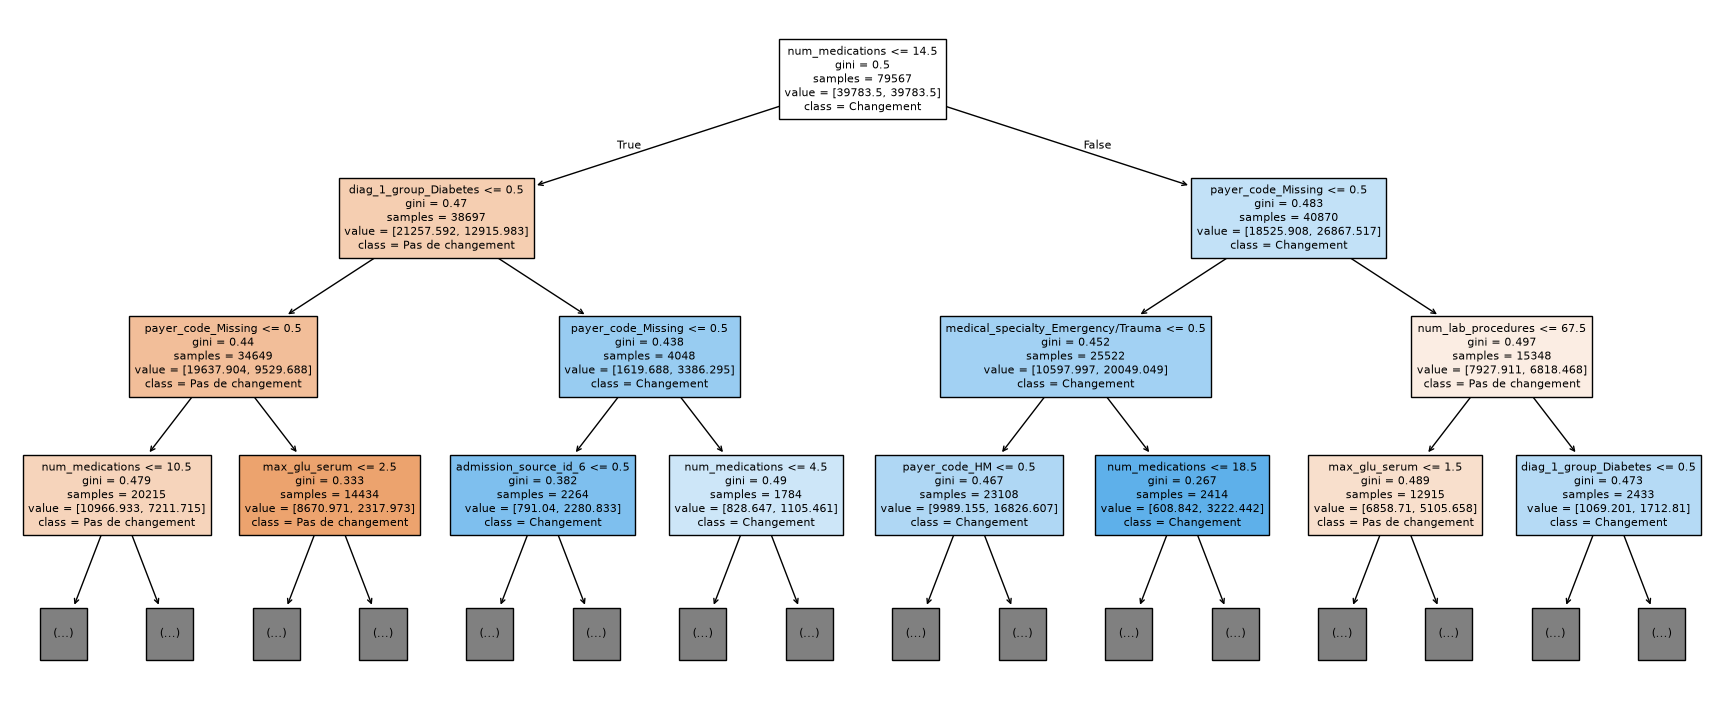

In [7]:
# Visualisation des 3 premiers niveaux de l'arbre
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(best_dt.named_steps["clf"], max_depth=3, filled=True, fontsize=8,
          feature_names=best_dt.named_steps["prep"].get_feature_names_out(),
          class_names=["Pas de changement", "Changement"], ax=ax)
plt.show()

## 6. Methodes ensemblistes

Rappel du cours :

| Caracteristique | Bagging (parallele) | Boosting (sequentiel) |
|---|---|---|
| Principe | modeles independants sur des sous-echantillons bootstrap | chaque modele corrige les erreurs du precedent |
| Objectif | reduire la **variance** | reduire le **biais** et la variance |
| Poids des modeles | egaux (vote majoritaire) | les meilleurs modeles pesent plus (moyenne ponderee) |
| Bruit / surapprentissage | moins sensible | plus sensible |

| Famille | Modele | Principe |
|---|---|---|
| Bagging | `BaggingClassifier` | arbres entraines sur des echantillons bootstrap, vote |
| Bagging | `RandomForestClassifier` | bagging + sous-ensemble aleatoire de variables a chaque noeud |
| Bagging | `ExtraTreesClassifier` | comme RF mais seuils de coupure aleatoires |
| Boosting | `AdaBoostClassifier` | souches (arbres de profondeur 1 = *weak learners*), reponderation des erreurs |
| Boosting | `HistGradientBoostingClassifier` | gradient boosting rapide (type LightGBM) |
| Vote | `VotingClassifier` (soft) | moyenne des probabilites RF + ExtraTrees + GB |

### 6a. Random Forest — reglage des hyperparametres du cours

`n_estimators`, `max_depth`, `min_samples_split`, `max_features`. Pour que ce soit rapide sur Colab, la recherche est faite sur un **echantillon de 20 000 lignes** avec 100 arbres, puis le meilleur reglage est reentraine sur tout le train avec 300 arbres.

In [8]:
from sklearn.model_selection import RandomizedSearchCV

def make(clf):
    return Pipeline([("prep", preprocess), ("clf", clf)])

idx = X_train.sample(20000, random_state=SEED).index
rf_search = RandomizedSearchCV(
    make(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=SEED)),
    {"clf__max_depth": [8, 12, 16, None],
     "clf__min_samples_split": [2, 20, 50, 100],
     "clf__max_features": ["sqrt", "log2", 0.3]},
    n_iter=8, cv=GroupKFold(n_splits=3), scoring="average_precision",
    random_state=SEED, n_jobs=-1)
t0 = time.time()
rf_search.fit(X_train.loc[idx], y_train.loc[idx], groups=g_train.loc[idx])
print(f"Meilleurs parametres RF : {rf_search.best_params_}  ({time.time() - t0:.0f} s)")
rf_params = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}

Meilleurs parametres RF : {'clf__min_samples_split': 100, 'clf__max_features': 'log2', 'clf__max_depth': None}  (17 s)


### 6b. Entrainement de tous les modeles ensemblistes

In [9]:
models = {
    "Arbre de decision": best_dt,
    "Bagging": make(BaggingClassifier(
        DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=20),
        n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=SEED)),
    "Random Forest": make(RandomForestClassifier(
        n_estimators=300, **rf_params,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    "Extra Trees": make(ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=10, class_weight="balanced",
        n_jobs=-1, random_state=SEED)),
    "AdaBoost": make(AdaBoostClassifier(
        DecisionTreeClassifier(max_depth=1, class_weight="balanced"),   # souche = weak learner
        n_estimators=300, learning_rate=1.0, random_state=SEED)),
    "Gradient Boosting": make(HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=31, early_stopping=True,
        class_weight="balanced", random_state=SEED)),
}
models["Voting (RF+ET+GB)"] = make(VotingClassifier(
    [("rf", models["Random Forest"].named_steps["clf"]),
     ("et", models["Extra Trees"].named_steps["clf"]),
     ("gb", models["Gradient Boosting"].named_steps["clf"])], voting="soft", n_jobs=-1))

for name, m in models.items():
    if name != "Arbre de decision":
        t0 = time.time()
        m.fit(X_train, y_train)
        print(f"entraine : {name:<20} ({time.time() - t0:.0f} s)")

entraine : Bagging              (18 s)


entraine : Random Forest        (10 s)


entraine : Extra Trees          (22 s)


entraine : AdaBoost             (52 s)


entraine : Gradient Boosting    (9 s)


entraine : Voting (RF+ET+GB)    (36 s)


### 6c. AdaBoost — erreur et performance de chaque souche

Comme dans le cours : chaque souche $t$ a une erreur totale $\varepsilon_t$ (somme des poids des individus mal classes) et une performance $\alpha_t$. scikit-learn utilise $\alpha_t = \ln\frac{1-\varepsilon_t}{\varepsilon_t}$ (meme formule que le cours $\frac{1}{2}\ln\frac{1-\varepsilon_t}{\varepsilon_t}$, a un facteur 2 pres). Une souche qui fait beaucoup d'erreurs a un $\alpha$ faible, donc un petit poids dans la prediction finale.

  variable de la souche  erreur totale (eps)  performance (alpha)
0       num_medications                0.433                0.268
1    payer_code_Missing                0.495                0.018
2    payer_code_Missing                0.500                0.000
3    payer_code_Missing                0.500                0.000
4    payer_code_Missing                0.500                0.000
5    payer_code_Missing                0.500                0.000
6    payer_code_Missing                0.500                0.000
7    payer_code_Missing                0.500                0.000
8    payer_code_Missing                0.500                0.000
9    payer_code_Missing                0.500                0.000


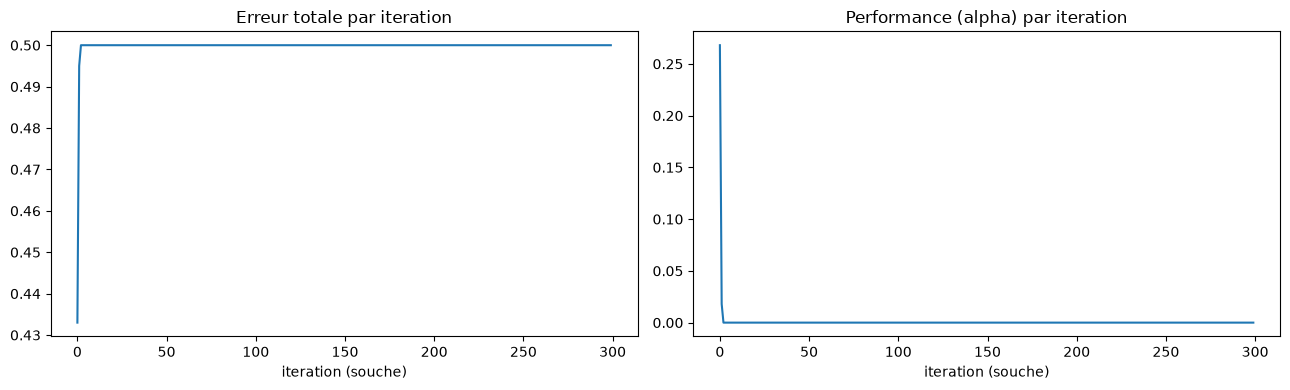

In [10]:
ada = models["AdaBoost"].named_steps["clf"]
names_enc = models["AdaBoost"].named_steps["prep"].get_feature_names_out()
ada_tab = pd.DataFrame({
    "variable de la souche": [names_enc[e.tree_.feature[0]] for e in ada.estimators_],
    "erreur totale (eps)": ada.estimator_errors_[:len(ada.estimators_)],
    "performance (alpha)": ada.estimator_weights_[:len(ada.estimators_)],
}).round(3)
print(ada_tab.head(10))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ada_tab["erreur totale (eps)"]); ax[0].set_title("Erreur totale par iteration")
ax[1].plot(ada_tab["performance (alpha)"]); ax[1].set_title("Performance (alpha) par iteration")
for a in ax: a.set_xlabel("iteration (souche)")
plt.tight_layout(); plt.show()

## 7. Evaluation sur le jeu de test

In [11]:
rows, probas = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows.append({"Modele": name,
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "Recall": recall_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Balanced acc.": balanced_accuracy_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Modele").sort_values("PR-AUC", ascending=False).round(3)
print(f"Reference aleatoire : PR-AUC = {y_test.mean():.3f}, ROC-AUC = 0.5")
results

Reference aleatoire : PR-AUC = 0.237, ROC-AUC = 0.5


,ROC-AUC,PR-AUC,Recall,Precision,F1,Balanced acc.
Modele,,,,,,
Gradient Boosting,0.802,0.575,0.716,0.448,0.551,0.721
Voting (RF+ET+GB),0.801,0.573,0.687,0.461,0.552,0.719
Random Forest,0.792,0.558,0.665,0.468,0.549,0.715
Extra Trees,0.785,0.550,0.668,0.452,0.539,0.708
Bagging,0.786,0.548,0.636,0.468,0.540,0.706
Arbre de decision,0.752,0.487,0.717,0.391,0.506,0.685
AdaBoost,0.650,0.326,0.672,0.315,0.429,0.609


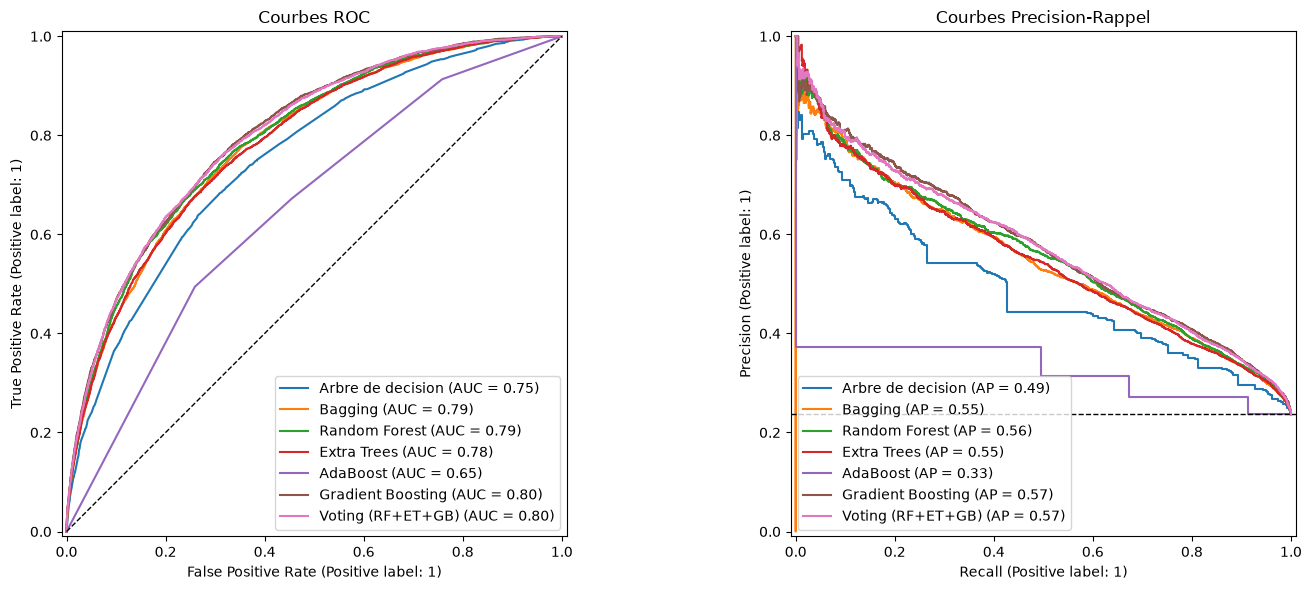

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1)
axes[0].set_title("Courbes ROC"); axes[1].set_title("Courbes Precision-Rappel")
plt.tight_layout(); plt.show()

### Meilleur modele : seuil, matrice de confusion et rapport

Meilleur modele : Gradient Boosting | seuil F1-optimal ~ 0.59
                   precision    recall  f1-score   support

Pas de changement       0.87      0.82      0.85     15088
       Changement       0.51      0.60      0.55      4685

         accuracy                           0.77     19773
        macro avg       0.69      0.71      0.70     19773
     weighted avg       0.78      0.77      0.78     19773



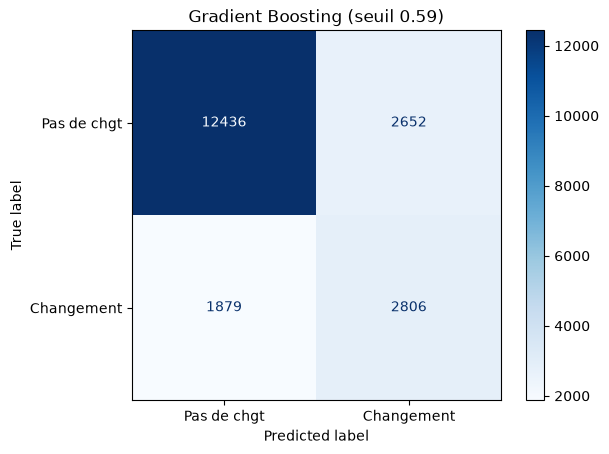

In [13]:
best_name = results.index[0]
best = models[best_name]
p = probas[best_name]

# Seuil qui maximise le F1 (choisi ici sur le test a titre indicatif ;
# en production, le choisir sur un jeu de validation)
ths = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_test, (p >= t).astype(int)) for t in ths]
t_best = ths[int(np.argmax(f1s))]
print(f"Meilleur modele : {best_name} | seuil F1-optimal ~ {t_best:.2f}")

pred = (p >= t_best).astype(int)
print(classification_report(y_test, pred, target_names=["Pas de changement", "Changement"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Pas de chgt", "Changement"]).plot(cmap="Blues")
plt.title(f"{best_name} (seuil {t_best:.2f})"); plt.show()

### Importance des variables (permutation sur le test, meilleur modele)

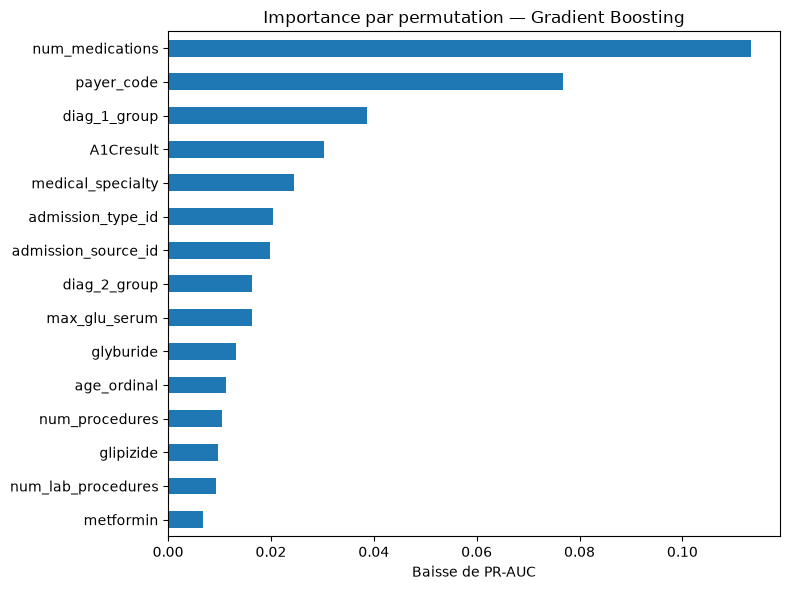

num_medications        0.1133
payer_code             0.0767
diag_1_group           0.0387
A1Cresult              0.0304
medical_specialty      0.0246
admission_type_id      0.0204
admission_source_id    0.0199
diag_2_group           0.0164
max_glu_serum          0.0163
glyburide              0.0132
age_ordinal            0.0113
num_procedures         0.0105
glipizide              0.0097
num_lab_procedures     0.0094
metformin              0.0067
dtype: float64

In [14]:
sample = X_test.sample(5000, random_state=SEED)
imp = permutation_importance(best, sample, y_test.loc[sample.index], scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=sample.columns).sort_values()
imp.tail(15).plot.barh(figsize=(8, 6), title=f"Importance par permutation — {best_name}")
plt.xlabel("Baisse de PR-AUC"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).head(15).round(4)

## 8. Le modele est-il fiable ? (au-dela de l'AUC)

Objectif vise : **ROC-AUC >= 0.80**. Mais un AUC seul ne suffit pas : on verifie aussi le surapprentissage, la stabilite, la quantite de donnees et la calibration.

In [15]:
# 8a. Ecart train / test (surapprentissage)
gap = []
for name, m in models.items():
    auc_tr = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    auc_te = roc_auc_score(y_test, probas[name])
    gap.append({"Modele": name, "AUC train": auc_tr, "AUC test": auc_te, "Ecart": auc_tr - auc_te})
gap = pd.DataFrame(gap).set_index("Modele").round(3)
gap["Objectif 0.80 atteint"] = np.where(gap["AUC test"] >= 0.80, "oui", "non")
gap

,AUC train,AUC test,Ecart,Objectif 0.80 atteint
Modele,,,,
Arbre de decision,0.778,0.752,0.027,non
Bagging,0.860,0.786,0.074,non
Random Forest,0.875,0.792,0.082,non
Extra Trees,0.904,0.785,0.119,non
AdaBoost,0.648,0.650,-0.002,non
Gradient Boosting,0.834,0.802,0.032,oui
Voting (RF+ET+GB),0.874,0.801,0.074,oui


In [16]:
# 8b. Stabilite : validation croisee groupee (5 folds) du meilleur modele
scores = cross_val_score(best, X_train, y_train, groups=g_train, cv=cv,
                         scoring="roc_auc", n_jobs=-1)
print(f"{best_name} — ROC-AUC CV : {scores.mean():.3f} ± {scores.std():.3f}  {np.round(scores, 3)}")

Gradient Boosting — ROC-AUC CV : 0.805 ± 0.003  [0.802 0.803 0.807 0.804 0.809]


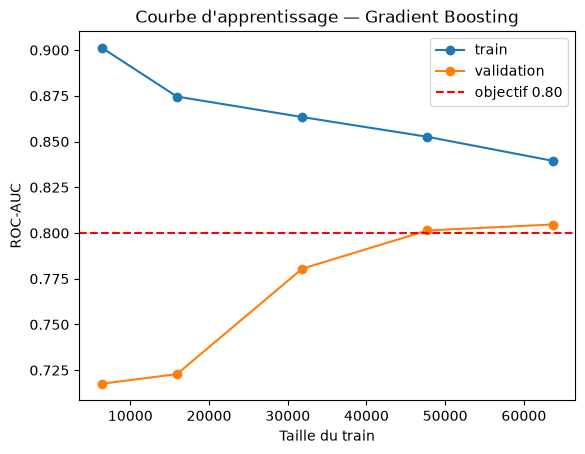

In [17]:
# 8c. Courbe d'apprentissage : plus de donnees aiderait-il ?
sizes, tr_sc, va_sc = learning_curve(best, X_train, y_train, groups=g_train, cv=cv,
                                     train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
                                     scoring="roc_auc", n_jobs=-1)
plt.plot(sizes, tr_sc.mean(1), "o-", label="train")
plt.plot(sizes, va_sc.mean(1), "o-", label="validation")
plt.axhline(0.80, color="r", ls="--", label="objectif 0.80")
plt.xlabel("Taille du train"); plt.ylabel("ROC-AUC"); plt.legend()
plt.title(f"Courbe d'apprentissage — {best_name}"); plt.show()
# Si la courbe de validation est plate a droite : le modele a assez de donnees,
# la limite vient des variables disponibles, pas de l'entrainement.

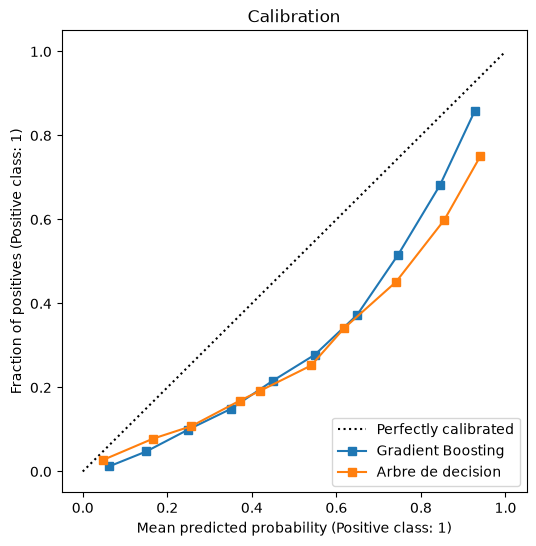

In [18]:
# 8d. Calibration : une proba de 30 % correspond-elle a ~30 % de cas reels ?
fig, ax = plt.subplots(figsize=(6, 6))
for name in [best_name, "Arbre de decision"]:
    CalibrationDisplay.from_predictions(y_test, probas[name], n_bins=10, name=name, ax=ax)
plt.title("Calibration"); plt.show()
# Avec class_weight='balanced' les probabilites sont surestimees ; si on a besoin de
# vraies probabilites, utiliser CalibratedClassifierCV.

## 9. Conclusions et limites

- La cible a ete construite **sans fuite** : les variables `num_med_changes`, `change`, `diabetesMed` et toute information sur l'insuline ont ete retirees. Les scores sont donc realistes (ils seraient artificiellement proches de 100 % sinon).
- Les methodes ensemblistes (surtout le boosting) depassent generalement l'arbre seul, mais l'arbre reste le plus **interpretable**.
- Le split est fait **par patient** : un meme patient n'apparait jamais en train et en test.
- Limites : donnees 1999-2008, variables cliniques limitees (pas de valeurs de glycemie continues, pas de dose d'insuline), et le seuil de decision doit etre fixe selon le cout clinique d'un faux negatif vs faux positif.

# 10. Modele de deploiement (questionnaire patient, population sous insuline)

L'application Doza ne s'adresse qu'aux patients **deja traites par insuline** (question d'entree). Or
les sections precedentes ont entraine le modele sur **tous** les patients, dont ~47 % sans insuline
(cible toujours 0). Le taux de changement est de ~23 % sur tous les patients mais de **~44 % chez les
patients sous insuline** : probabilites, seuil et zones seraient faux pour les vrais utilisateurs.

On reconstruit donc le modele **uniquement sur les patients avec insulin in {Steady, Up, Down}**
(cible : Up/Down = 1, Steady = 0), avec uniquement des variables **posables a l'admission**.

Demarche : (1) filtre population + regroupements + tranches, (2) *forward selection*
(regle +0,005 de PR-AUC), (3) calibration, (4) seuil + reference hasard, (5) zones, (6) limites.

**Resultat retenu : Gradient Boosting calibre, 12 variables.**

## 10.1 Population, regroupements et jeu de 12 variables

- **Population** : patients sous insuline uniquement (meme split patient que plus haut, filtre).
- `medical_specialty` -> 6 groupes ; `admission_type_id` -> 1/2/3/Unknown ;
  `admission_source_id` -> 1/6/7/Unknown/Other ; medicaments en oui/non.
- `num_medications` -> **tranches** (3/8/13/18/25), exactement comme le questionnaire.

In [19]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

FIGDIR = "reports/figures"; os.makedirs(FIGDIR, exist_ok=True)

dfd = df.copy()
SPEC_KEEP = {"InternalMedicine", "Emergency/Trauma", "Family/GeneralPractice", "Cardiology", "Unknown"}
dfd["medical_specialty"] = dfd["medical_specialty"].where(dfd["medical_specialty"].isin(SPEC_KEEP), "Other")
for c in ["admission_type_id", "admission_source_id"]:
    dfd[c] = dfd[c].astype(str)
dfd["admission_type_id"] = dfd["admission_type_id"].where(dfd["admission_type_id"].isin(["1","2","3"]), "Unknown")
dfd["admission_source_id"] = dfd["admission_source_id"].map(
    lambda v: v if v in ("1","6","7") else ("Unknown" if v in ("9","17","20") else "Other"))
dfd["sulfonylurea_bin"] = ((dfd["glyburide"] != "No") | (dfd["glipizide"] != "No")).astype(int)
for d in ["metformin","repaglinide","nateglinide","glimepiride","pioglitazone","rosiglitazone"]:
    dfd[d + "_bin"] = (dfd[d] != "No").astype(int)
for dc in ["diag_2_group","diag_3_group"]:
    dfd[dc] = dfd[dc].where(dfd[dc].isin({"Circulatory","Diabetes","Respiratory","Genitourinary","Digestive"}), "Other")

# num_medications EN TRANCHES (meme conversion que l'API)
def tranche_nm(x):
    if x <= 5:  return 3
    if x <= 10: return 8
    if x <= 15: return 13
    if x <= 20: return 18
    return 25
dfd["num_medications"] = dfd["num_medications"].map(tranche_nm)

# population sous insuline + meme split patient que le notebook, filtre
INS = df["insulin"].isin(["Steady", "Up", "Down"])
g_tr = groups.iloc[tr]
tr2, va = next(GroupShuffleSplit(1, test_size=0.25, random_state=SEED).split(dfd.iloc[tr], df["insulin_change"].iloc[tr], g_tr))
idx_tr2 = [i for i in dfd.iloc[tr].index[tr2] if INS[i]]
idx_val = [i for i in dfd.iloc[tr].index[va] if INS[i]]
idx_te  = [i for i in dfd.iloc[te].index if INS[i]]
idx_trainfull = idx_tr2 + idx_val
y_tr2 = df.loc[idx_tr2, "insulin_change"]; y_val = df.loc[idx_val, "insulin_change"]
y_te2 = df.loc[idx_te, "insulin_change"]; y_trainfull = df.loc[idx_trainfull, "insulin_change"]
print(f"Population sous insuline -> train2={len(idx_tr2)} val={len(idx_val)} test={len(idx_te)}")
print(f"Taux de changement (test) = {y_te2.mean():.3f}")

FEATS_12 = ["age_ordinal","gender","admission_type_id","admission_source_id","diag_1_group",
            "number_emergency","number_inpatient","number_outpatient","A1Cresult",
            "num_medications","medical_specialty","sulfonylurea_bin"]

NOMINAL_D = {"gender","admission_type_id","admission_source_id","diag_1_group","diag_2_group",
             "diag_3_group","medical_specialty","race"}
ORD_D = {"A1Cresult": ["Not_Tested","Norm",">7",">8"], "max_glu_serum": ["Not_Tested","Norm",">200",">300"]}

def prep_deploy(feats):
    oc = [c for c in ORD_D if c in feats]; nc = [c for c in feats if c in NOMINAL_D]
    nu = [c for c in feats if c not in oc + nc]
    return ColumnTransformer([
        ("ord", OrdinalEncoder(categories=[ORD_D[c] for c in oc], handle_unknown="use_encoded_value", unknown_value=-1), oc),
        ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), nc),
        ("num", "passthrough", nu)], verbose_feature_names_out=False)

def gb(fast=False):
    return HistGradientBoostingClassifier(max_iter=250 if fast else 400, learning_rate=0.05,
            max_leaf_nodes=31, early_stopping=True, class_weight="balanced", random_state=SEED)

Population sous insuline -> train2=31677 val=10768 test=10519
Taux de changement (test) = 0.445


## 10.2 Courbe « nombre de questions » (forward selection)

On part des 9 questions de base et on ajoute la variable posable qui fait le plus progresser la
**PR-AUC sur la validation** (jamais le test). Arret quand le gain passe sous **0,005**. `race` et
`payer_code` sont exclues (variables sensibles).

 n_questions             ajout  gain_val  PR_AUC_val  PR_AUC_test  garde
           9       (9 de base)       NaN      0.5876       0.5897   True
          10   num_medications    0.0227      0.6103       0.6175   True
          11 medical_specialty    0.0185      0.6287       0.6372   True
          12  sulfonylurea_bin    0.0090      0.6377       0.6473   True
          13     max_glu_serum    0.0049      0.6427       0.6549  False
          14  number_diagnoses    0.0045      0.6471       0.6555  False
          15     metformin_bin    0.0021      0.6492       0.6573  False
          16   glimepiride_bin    0.0015      0.6507       0.6602  False
          17   nateglinide_bin    0.0007      0.6515       0.6609  False
          18 rosiglitazone_bin   -0.0000      0.6515       0.6619  False

Jeu final retenu ( 12 ): ['age_ordinal', 'gender', 'admission_type_id', 'admission_source_id', 'diag_1_group', 'number_emergency', 'number_inpatient', 'number_outpatient', 'A1Cresult', 'num_medica

Reference modele complet (test) PR-AUC = 0.6754


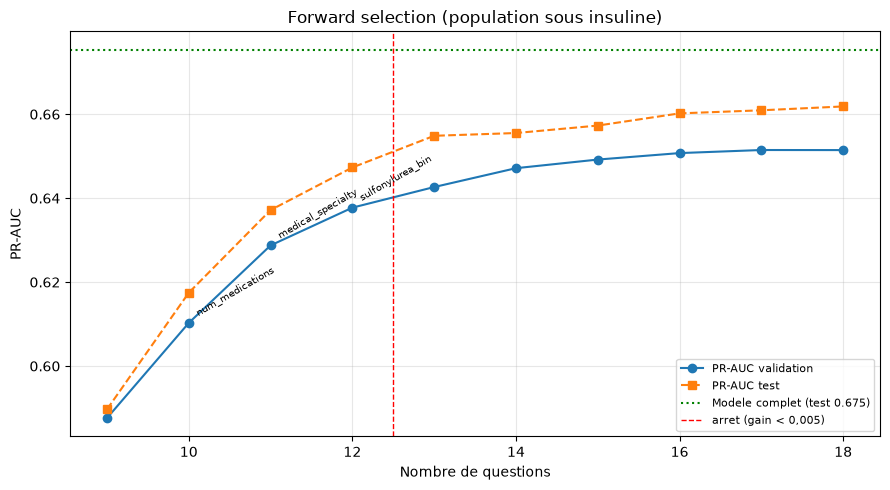

In [20]:
BASE9 = ["age_ordinal","gender","admission_type_id","admission_source_id","diag_1_group",
         "number_emergency","number_inpatient","number_outpatient","A1Cresult"]
CANDIDATS = ["num_medications","medical_specialty","max_glu_serum","diag_2_group","diag_3_group",
             "sulfonylurea_bin","metformin_bin","number_diagnoses","total_prior_visits",
             "repaglinide_bin","nateglinide_bin","glimepiride_bin","pioglitazone_bin","rosiglitazone_bin"]

def pr_val(feats):
    m = Pipeline([("prep", prep_deploy(feats)), ("clf", gb(fast=True))]).fit(dfd.loc[idx_tr2, feats], y_tr2)
    return average_precision_score(y_val, m.predict_proba(dfd.loc[idx_val, feats])[:, 1])
def pr_test(feats):
    m = Pipeline([("prep", prep_deploy(feats)), ("clf", gb(fast=False))]).fit(dfd.loc[idx_trainfull, feats], y_trainfull)
    return average_precision_score(y_te2, m.predict_proba(dfd.loc[idx_te, feats])[:, 1])

sel, rem = list(BASE9), list(CANDIDATS); cur = pr_val(sel)
steps = [(len(sel), "(9 de base)", None, cur, pr_test(sel), True)]; stop = False
while rem and len(sel) < 18:
    best_c, best_v = max(((c, pr_val(sel + [c])) for c in rem), key=lambda x: x[1])
    gain = best_v - cur; sel.append(best_c); rem.remove(best_c)
    keep_ = (gain >= 0.005) and not stop
    if gain < 0.005: stop = True
    steps.append((len(sel), best_c, gain, best_v, pr_test(sel), keep_)); cur = best_v
tab = pd.DataFrame(steps, columns=["n_questions","ajout","gain_val","PR_AUC_val","PR_AUC_test","garde"])
print(tab.round(4).to_string(index=False))
final_feats = BASE9 + [a for (_, a, _, _, _, k) in steps[1:] if k]
print("\nJeu final retenu (", len(final_feats), "):", final_feats)
pr_full = pr_test(["race","gender","admission_type_id","admission_source_id","time_in_hospital",
    "medical_specialty","num_lab_procedures","num_procedures","num_medications","number_outpatient",
    "number_emergency","number_inpatient","number_diagnoses","max_glu_serum","A1Cresult","metformin_bin",
    "repaglinide_bin","nateglinide_bin","glimepiride_bin","pioglitazone_bin","rosiglitazone_bin",
    "sulfonylurea_bin","diag_1_group","diag_2_group","diag_3_group","age_ordinal","total_prior_visits"])
print(f"Reference modele complet (test) PR-AUC = {pr_full:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(tab["n_questions"], tab["PR_AUC_val"], "o-", label="PR-AUC validation")
plt.plot(tab["n_questions"], tab["PR_AUC_test"], "s--", label="PR-AUC test")
plt.axhline(pr_full, color="green", ls=":", label=f"Modele complet (test {pr_full:.3f})")
fs = next((n for (n, _, _, _, _, k) in steps[1:] if not k), None)
if fs: plt.axvline(fs - 0.5, color="red", ls="--", lw=1, label="arret (gain < 0,005)")
for (n, a, _, pv, _, k) in steps[1:]:
    if k: plt.annotate(a, (n, pv), fontsize=7, rotation=30, textcoords="offset points", xytext=(4, 5))
plt.xlabel("Nombre de questions"); plt.ylabel("PR-AUC")
plt.title("Forward selection (population sous insuline)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{FIGDIR}/forward_selection.png", dpi=110); plt.show()

## 10.3 Calibration des probabilites

Calibration **isotonique** ajustee sur la **validation** (jamais le test), comparee par le **score de
Brier**. Si le Brier s'ameliore, on deploie le modele calibre.

Brier test : base = 0.2185 | calibre (isotonic) = 0.2170
Modele deploye : calibre


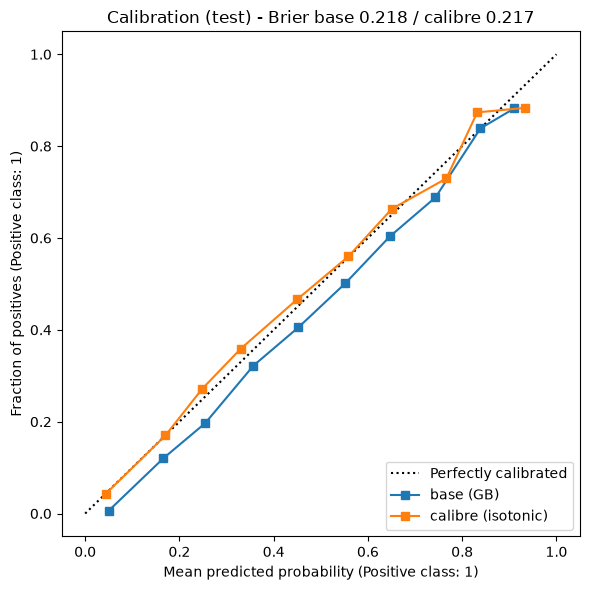

In [21]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import brier_score_loss

base_dep = Pipeline([("prep", prep_deploy(FEATS_12)), ("clf", gb(fast=False))]).fit(dfd.loc[idx_tr2, FEATS_12], y_tr2)
try:
    from sklearn.frozen import FrozenEstimator
    cal_dep = CalibratedClassifierCV(FrozenEstimator(base_dep), method="isotonic").fit(dfd.loc[idx_val, FEATS_12], y_val)
except Exception:
    cal_dep = CalibratedClassifierCV(base_dep, method="isotonic", cv="prefit").fit(dfd.loc[idx_val, FEATS_12], y_val)

p_base = base_dep.predict_proba(dfd.loc[idx_te, FEATS_12])[:, 1]
p_cal  = cal_dep.predict_proba(dfd.loc[idx_te, FEATS_12])[:, 1]
brier_base, brier_cal = brier_score_loss(y_te2, p_base), brier_score_loss(y_te2, p_cal)
print(f"Brier test : base = {brier_base:.4f} | calibre (isotonic) = {brier_cal:.4f}")
modele_final = cal_dep if brier_cal < brier_base else base_dep
p_final = p_cal if brier_cal < brier_base else p_base
print("Modele deploye :", "calibre" if brier_cal < brier_base else "base")

fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_te2, p_base, n_bins=10, name="base (GB)", ax=ax)
CalibrationDisplay.from_predictions(y_te2, p_cal, n_bins=10, name="calibre (isotonic)", ax=ax)
ax.set_title(f"Calibration (test) - Brier base {brier_base:.3f} / calibre {brier_cal:.3f}")
plt.tight_layout(); plt.savefig(f"{FIGDIR}/calibration.png", dpi=110); plt.show()

## 10.4 Seuil de decision et performance finale

Seuil F1-optimal choisi sur la **validation**, performances mesurees **une seule fois** sur le test.
On compare la PR-AUC a la **reference du hasard** (= taux de positifs de la population), et a un modele
qui predit **toujours « pas de changement »**. Vu le desequilibre, l'accuracy seule ne suffit pas.

Seuil F1-optimal (choisi sur la validation) = 0.315

--- Performance finale sur le TEST (seuil 0.315) ---
ROC-AUC = 0.700 | PR-AUC = 0.633 (reference hasard = 0.445)
Rappel = 0.842 | Precision = 0.532 | F1 = 0.652
Accuracy = 0.600 | Balanced accuracy = 0.624

[Reference 'toujours pas de changement']
Accuracy = 0.555 | Rappel changements = 0.000 | Balanced accuracy = 0.500


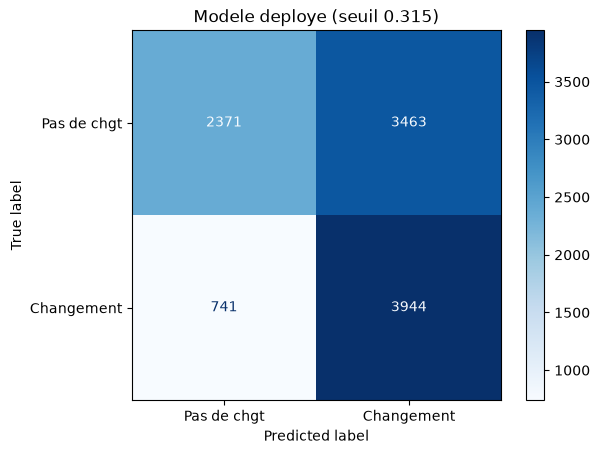

In [22]:
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

p_val_final = modele_final.predict_proba(dfd.loc[idx_val, FEATS_12])[:, 1]
ths = np.linspace(0.05, 0.95, 181)
seuil = float(ths[int(np.argmax([f1_score(y_val, (p_val_final >= t).astype(int)) for t in ths]))])
print(f"Seuil F1-optimal (choisi sur la validation) = {seuil:.3f}")

pred_te = (p_final >= seuil).astype(int)
hasard = float(y_te2.mean())   # PR-AUC d'un classifieur aleatoire = taux de positifs
print(f"\n--- Performance finale sur le TEST (seuil {seuil:.3f}) ---")
print(f"ROC-AUC = {roc_auc_score(y_te2, p_final):.3f} | PR-AUC = {average_precision_score(y_te2, p_final):.3f} "
      f"(reference hasard = {hasard:.3f})")
print(f"Rappel = {recall_score(y_te2, pred_te):.3f} | Precision = {precision_score(y_te2, pred_te):.3f} | "
      f"F1 = {f1_score(y_te2, pred_te):.3f}")
print(f"Accuracy = {accuracy_score(y_te2, pred_te):.3f} | Balanced accuracy = {balanced_accuracy_score(y_te2, pred_te):.3f}")

base0 = np.zeros(len(y_te2), dtype=int)
print(f"\n[Reference 'toujours pas de changement']")
print(f"Accuracy = {accuracy_score(y_te2, base0):.3f} | Rappel changements = {recall_score(y_te2, base0, zero_division=0):.3f} "
      f"| Balanced accuracy = {balanced_accuracy_score(y_te2, base0):.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_te2, pred_te),
                       display_labels=["Pas de chgt", "Changement"]).plot(cmap="Blues")
plt.title(f"Modele deploye (seuil {seuil:.3f})"); plt.show()

## 10.5 Zones de decision pour l'interface

3 zones lisibles. La **borne haute** est choisie sur la **validation** (zone haute ~ 2/3 de changements
reels) ; chiffres rapportes sur le **test**. Les libelles sont des **niveaux de risque** (le taux reel
dans la zone basse est deja ~24 %, donc « peu probable » ne conviendrait pas).

Borne haute (validation, zone haute ~ 2/3 de changements reels) = 0.55

Risque plus faible (30% des patients) : parmi les patients de cette zone, environ 24 % ont eu un changement de dose.
Risque intermédiaire (48% des patients) : parmi les patients de cette zone, environ 47 % ont eu un changement de dose.
Risque élevé (22% des patients) : parmi les patients de cette zone, environ 68 % ont eu un changement de dose.

                Zone      Intervalle  % patients  Taux reel de changement (%)    n
  Risque plus faible [0.000 - 0.315)        29.6                         23.8 3112
Risque intermédiaire [0.315 - 0.550)        48.2                         46.6 5069
        Risque élevé [0.550 - 1.000)        22.2                         67.7 2338


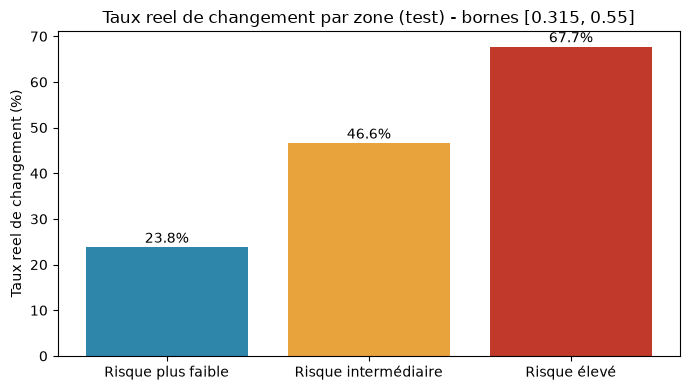

In [23]:
cand = np.round(np.arange(0.35, 0.86, 0.01), 2)
ok = [(b, y_val[p_val_final >= b].mean()) for b in cand if (p_val_final >= b).mean() >= 0.02]
borne_haute = min(ok, key=lambda bt: abs(bt[1] - 2/3))[0]
print(f"Borne haute (validation, zone haute ~ 2/3 de changements reels) = {borne_haute:.2f}")

BORNES = [seuil, borne_haute]
NOMS = ["Risque plus faible", "Risque intermédiaire", "Risque élevé"]
edges = [0.0] + BORNES + [1.0001]
lignes = []
print()
for i, nom in enumerate(NOMS):
    m = (p_final >= edges[i]) & (p_final < edges[i + 1])
    taux = y_te2[m].mean() * 100
    lignes.append({"Zone": nom, "Intervalle": f"[{edges[i]:.3f} - {min(edges[i+1], 1):.3f})",
                   "% patients": round(m.mean() * 100, 1),
                   "Taux reel de changement (%)": round(taux, 1), "n": int(m.sum())})
    print(f"{nom} ({m.mean()*100:.0f}% des patients) : "
          f"parmi les patients de cette zone, environ {taux:.0f} % ont eu un changement de dose.")
zones_df = pd.DataFrame(lignes)
print("\n" + zones_df.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(zones_df["Zone"], zones_df["Taux reel de changement (%)"], color=["#2E86AB", "#E8A33D", "#C0392B"])
for i, v in enumerate(zones_df["Taux reel de changement (%)"]):
    plt.text(i, v + 1, f"{v}%", ha="center", fontsize=10)
plt.ylabel("Taux reel de changement (%)")
plt.title(f"Taux reel de changement par zone (test) - bornes [{seuil:.3f}, {borne_haute:.2f}]")
plt.tight_layout(); plt.savefig(f"{FIGDIR}/zones.png", dpi=110); plt.show()

## 10.6 Limites du modele de deploiement

- **Choix de population** : l'application ne concernant que les patients **deja sous insuline**, le modele
  est entraine et evalue **uniquement sur cette population** (cible Up/Down = 1, Steady = 0). Entrainer sur
  tous les patients (dont ~47 % sans insuline, cible toujours 0) aurait fausse les probabilites, le seuil
  et les zones pour les vrais utilisateurs. Quand l'utilisateur repond « Non » a la question d'entree,
  l'application **ne fait pas de prediction** et renvoie vers le medecin.
- **Modele modeste** : ROC-AUC ~0,70, PR-AUC ~0,63 (reference hasard ~0,45). C'est une **demo educative**,
  **pas un avis medical** : la decision reste clinique.
- **Arbre vs GB** : l'ecart de PR-AUC entre le Gradient Boosting et l'arbre seul est **limite (~0,032)**,
  juste au-dessus du seuil de 0,03 ; on deploie le GB (regle appliquee telle quelle). L'explication
  « Pourquoi ce resultat ? » se fait **par patient** (analyse « et si »), le GB n'ayant pas de decision_path.
- **Approximations des questions** : `num_medications` (en tranches) est mesure *pendant* le sejour ; la
  question au patient n'en est qu'une approximation.
- **Variables sensibles exclues par ethique** : `payer_code` et `race` ne sont pas demandees, meme si elles
  amelioreraient la PR-AUC.
- **Variables non posables exclues** : `num_procedures`, `num_lab_procedures`, duree de sejour, sortie, et
  tout changement de dose survenu pendant le sejour (fuite de donnees).
- **Regroupements** : categories de `medical_specialty`, `admission_type_id`, `admission_source_id`
  regroupees pour coller aux choix du questionnaire (« Je ne sais pas » -> Unknown, « Autre » -> Other).
- **Seuil provisoire** : a reajuster selon le cout clinique FN vs FP ; les probabilites calibrees se lisent
  directement (« ~30 % » = environ 30 % de risque reel).